# Pydantic AI togheter with Pydantic Models 

In [ ]:
from model import changeModel
from pydantic_ai import Agent

from pydantic_ai.models.openai import OpenAIChatModel
from pydantic_ai.providers.openai import OpenAIProvider
import os
from dotenv import load_dotenv
load_dotenv()

True

In [12]:
employee_simulator = Agent(
    model = changeModel("nvidia/nemotron-3.5-super-vl-120b-a12b"), 
    instructions="Du är expert på att simulera anställda i Sverige. Simylera i detta formatet:"
    """
        name: "Bertil", 
        age: 40, 
        salary: 35000, 
        role: "IT-supporter", 
        ort: "Göteborg", 
    """
)

result = await employee_simulator.run(
    "Ge mig en data engineer som jobbar i Stockholm"
)

print(result.output)

name: "Erik", 
age: 38, 
salary: 54000, 
role: "Data engineer", 
ort: "Stockholm"


## Force an output using Pydantic 

In [14]:
from pydantic import BaseModel, Field 

In [21]:
class EmployeeModel(BaseModel): #Ärver från BaseModel 
    name: str = Field(description="För och efternamn, inte jättelångt, svenska eller internationella namn") #Specificera field och description för oss som kan läsas av oss och LLM 
    age: int = Field(description="Ålder från 18 till 67", ge=18, le=67) # greater equal & less equal 
    salary: int = Field(description="Lön mellan 30k-60k, ju mer senior position desto högre lön",
        ge=30_000, 
        le=60_000)
    role: str = Field(description="yrke/roll")
    description: str = Field("kort beskrivning, 2 meningar på rollen") 


employee1 = EmployeeModel(name="Bertil", age=50, salary=30000, role="IT-supporter", description="Hjälper folk med IT") 

employee1




EmployeeModel(name='Bertil', age=50, salary=30000, role='IT-supporter', description='Hjälper folk med IT')

In [22]:
employee_simulator = Agent(
    model = changeModel("nvidia/nemotron-3.5-super-vl-120b-a12b"), 
    instructions= "Du är expert på att simulera anställda i Sverige"

)


result = await employee_simulator.run("Ge mig en Data Engineer i Stockholm")


result.output

'Här är en simulerad personlig profil för en Data Engineer i Stockholm. Allt är fiktivt, men bygger på typiska drag för rollen på den svenska tech-marknaden.\n\n---\n\n### 👤 Personlig presentation\n\n**Namn:** Erik Johansson  \n**Ålder:** 32  \n**Titel:** Senior Data Engineer  \n**Företag:** En växande klimattech-scaleup med kontor i Hammarby Sjöstad, Stockholm  \n**Bor:** Södermalm (pendlar med T-bana, röda linjen, ca 20 minuter)  \n**Utbildning:** Civilingenjör i datateknik, KTH Royal Institute of Technology (examen 2016)  \n**Språk:** Svenska (modersmål), engelska (flytande – kontorsspråket är engelska)\n\n---\n\n### 🧰 Teknisk kompetens (typisk stack)\n\n| Kategori | Verktyg och teknologier |\n|----------|-------------------------|\n| **Programmering** | Python (pandas, polars, great_expectations), SQL |\n| **Datahantering** | PySpark, dbt, Snowflake / Google BigQuery |\n| **Orchestration** | Apache Airflow (Cloud Composer), Prefect (en del projekt) |\n| **Molnmiljö** | GCP (BigQuer

In [23]:
result = await employee_simulator.run("Ge mig en Data Engineer i Stockholm", output_type=EmployeeModel)

result

AgentRunResult(output=EmployeeModel(name='Erik Andersson', age=32, salary=52000, role='Data Engineer', description='Erik arbetar som Data Engineer på ett techbolag i Stockholm och ansvarar för att bygga och underhålla datapipelines i molnet. Han har erfarenhet av Python, SQL och AWS samt brinner för att skapa skalbara datalösningar som stödjer verksamhetens beslut.'))

In [26]:
employee2 = result.output
employee2

EmployeeModel(name='Erik Andersson', age=32, salary=52000, role='Data Engineer', description='Erik arbetar som Data Engineer på ett techbolag i Stockholm och ansvarar för att bygga och underhålla datapipelines i molnet. Han har erfarenhet av Python, SQL och AWS samt brinner för att skapa skalbara datalösningar som stödjer verksamhetens beslut.')

In [27]:
type(employee2)

__main__.EmployeeModel

In [28]:
employee2.name

'Erik Andersson'

In [40]:
for attributes in employee2: 
    print(attributes)

('name', 'Erik Andersson')
('age', 32)
('salary', 52000)
('role', 'Data Engineer')
('description', 'Erik arbetar som Data Engineer på ett techbolag i Stockholm och ansvarar för att bygga och underhålla datapipelines i molnet. Han har erfarenhet av Python, SQL och AWS samt brinner för att skapa skalbara datalösningar som stödjer verksamhetens beslut.')


In [32]:
employee2.__dict__.keys()

dict_keys(['name', 'age', 'salary', 'role', 'description'])

In [33]:
employee2.__dict__.values()

dict_values(['Erik Andersson', 32, 52000, 'Data Engineer', 'Erik arbetar som Data Engineer på ett techbolag i Stockholm och ansvarar för att bygga och underhålla datapipelines i molnet. Han har erfarenhet av Python, SQL och AWS samt brinner för att skapa skalbara datalösningar som stödjer verksamhetens beslut.'])

In [34]:
for key, value in employee2.__dict__.items():
    print(f"{key}: {value}")
    

name: Erik Andersson
age: 32
salary: 52000
role: Data Engineer
description: Erik arbetar som Data Engineer på ett techbolag i Stockholm och ansvarar för att bygga och underhålla datapipelines i molnet. Han har erfarenhet av Python, SQL och AWS samt brinner för att skapa skalbara datalösningar som stödjer verksamhetens beslut.


# simulate many employeer

In [43]:
result = await employee_simulator.run(
    "Ge mig totalt 10 anställda inom IT/HR/Marketing", 
    output_type=list[EmployeeModel]
)

result


{'output': [EmployeeModel(name='Erik Andersson', age=35, salary=48000, role='Systemutvecklare', description='Utvecklar och underhåller företagets webbapplikationer. Har lång erfarenhet av Java och molnlösningar.'),
  EmployeeModel(name='Sofia Karlsson', age=28, salary=34000, role='IT-supporttekniker', description='Hjälper kollegor med datorproblem och installationer. Ansvarar för första linjens support internt.'),
  EmployeeModel(name='Magnus Nilsson', age=42, salary=55000, role='IT-projektledare', description='Driver IT-projekt från idé till implementation. Samordnar utvecklare och intressenter.'),
  EmployeeModel(name='Lucas Müller', age=31, salary=46000, role='IT-säkerhetsspecialist', description='Säkerställer att företagets system är skyddade mot intrång. Genomför riskanalyser och säkerhetsuppdateringar.'),
  EmployeeModel(name='Amanda Berg', age=29, salary=36000, role='HR-assistent', description='Stödjer HR-avdelningen med administration och anställningar. Ansvarar för nyanställda

In [46]:
employees = result.output

employees

[EmployeeModel(name='Erik Andersson', age=35, salary=48000, role='Systemutvecklare', description='Utvecklar och underhåller företagets webbapplikationer. Har lång erfarenhet av Java och molnlösningar.'),
 EmployeeModel(name='Sofia Karlsson', age=28, salary=34000, role='IT-supporttekniker', description='Hjälper kollegor med datorproblem och installationer. Ansvarar för första linjens support internt.'),
 EmployeeModel(name='Magnus Nilsson', age=42, salary=55000, role='IT-projektledare', description='Driver IT-projekt från idé till implementation. Samordnar utvecklare och intressenter.'),
 EmployeeModel(name='Lucas Müller', age=31, salary=46000, role='IT-säkerhetsspecialist', description='Säkerställer att företagets system är skyddade mot intrång. Genomför riskanalyser och säkerhetsuppdateringar.'),
 EmployeeModel(name='Amanda Berg', age=29, salary=36000, role='HR-assistent', description='Stödjer HR-avdelningen med administration och anställningar. Ansvarar för nyanställdas introduktion.

In [ ]:


salarys = [] 
for em in employees:
    salarys.append(em.salary)
print(salarys)




[48000, 34000, 55000, 46000, 36000, 52000, 44000, 33000, 42000, 56000]


In [77]:
av = sum(salarys)/len(salarys)
print(av)

44600.0


# Convert to dataframe

In [78]:
employees[0].model_dump

<bound method BaseModel.model_dump of EmployeeModel(name='Erik Andersson', age=35, salary=48000, role='Systemutvecklare', description='Utvecklar och underhåller företagets webbapplikationer. Har lång erfarenhet av Java och molnlösningar.')>

In [83]:
import pandas as pd 
df = pd.DataFrame([employee.model_dump() for employee in employees])

df.head()

,name,age,salary,role,description
0,Erik Andersson,35,48000,Systemutvecklare,Utvecklar och underhåller företagets webbappli...
1,Sofia Karlsson,28,34000,IT-supporttekniker,Hjälper kollegor med datorproblem och installa...
2,Magnus Nilsson,42,55000,IT-projektledare,Driver IT-projekt från idé till implementation...
3,Lucas Müller,31,46000,IT-säkerhetsspecialist,Säkerställer att företagets system är skyddade...
4,Amanda Berg,29,36000,HR-assistent,Stödjer HR-avdelningen med administration och ...


In [84]:
df.to_csv("employees.csv", index=None)

<Axes: ylabel='name'>

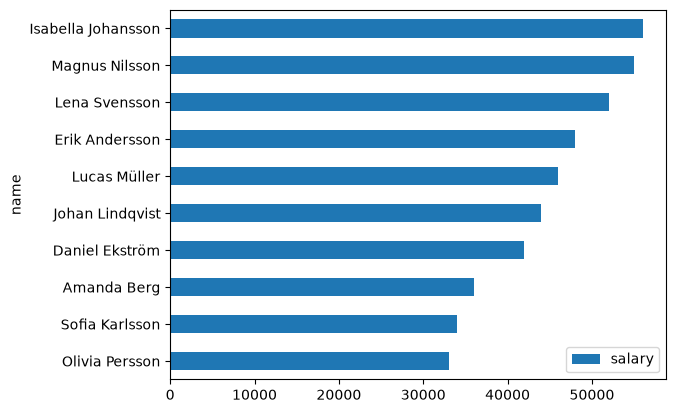

In [95]:
df.sort_values("salary", ascending=True).plot(kind="barh", x="name", y="salary") 